# DATA 621 Homework 3: Crime Risk Prediction with Logistic Regression

## Project Objective
This project's objective is to build binary logistic regression models using the crime training data to predict whether a neighborhood's crime rate is above the median (`target = 1`) or not (`target = 0`). Evaluate and select a model, then use it to generate classifications and predicted probabilities for the evaluation data, applying a 0.5 classification threshold.

# 1. Load Data/EDA
## 1.1 Dataset Overview & Data Quality Assessment:

To complete this assignement the datasets were first uploaded to the group GitHub repository and then loaded directly from the raw GitHub URL using `pandas`. This ensures the notebook is 100% reproducible without requiring local file downloads.

We started by importing the core Python libraries needed for data manipulation and visualization, and loading the training dataset directly from the GitHub repository.

Before we model, we must verify the size, scope, and integrity of our data. A model built on incomplete data cannot be trusted in production.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for executive-ready visuals
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load the datasets
train_url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/main/homeworks/hw03/data/crime-training-data_modified.csv"
train_df = pd.read_csv(train_url)

# 1. Size and Scope
print(f"Dataset Size: {train_df.shape[0]} neighborhoods and {train_df.shape[1]} variables.")

# 2. Data Quality (Missing Values)
missing_data = train_df.isnull().sum().sum()
if missing_data == 0:
    print("Data Quality: Excellent. There are 0 missing values across all columns. No imputation is required.")
else:
    print(f"Data Quality Warning: {missing_data} missing values detected.")

Dataset Size: 466 neighborhoods and 13 variables.
Data Quality: Excellent. There are 0 missing values across all columns. No imputation is required.


## 1.2 The Target Variable & Baseline Statistics

Our goal is to predict whether a neighborhood is at risk for high crime (`target = 1`). We need to establish if our data is skewed toward one outcome, and look at the baseline averages for key neighborhood metrics.

In [3]:
# Target Variable Balance
target_counts = train_df['target'].value_counts(normalize=True) * 100
print(f"Target Balance: {target_counts[0]:.1f}% Low Crime (0) | {target_counts[1]:.1f}% High Crime (1)")

# Executive Summary Stats for Key Variables
key_vars = ['nox', 'age', 'tax', 'dis', 'medv']
summary_stats = train_df[key_vars].agg(['mean', 'median', 'std']).round(2).T
print("\n--- Baseline Neighborhood Statistics ---")
display(summary_stats)

Target Balance: 50.9% Low Crime (0) | 49.1% High Crime (1)

--- Baseline Neighborhood Statistics ---


,mean,median,std
nox,0.55,0.54,0.12
age,68.37,77.15,28.32
tax,409.50,334.50,167.90
dis,3.80,3.19,2.11
medv,22.59,21.20,9.24


The data is almost perfectly split (51% low crime, 49% high crime). This is ideal. We will not need to use complex class-balancing techniques (like oversampling) that can distort model accuracy.

We observe wide variances in housing age (`age`) and property taxes (`tax`). The median and mean for variables like `dis` differ noticeably, indicating skew in the data that we may need to transform before modeling.

## 1.3 Visualizing Key Drivers of Crime

Rather than plotting every single variable, we focus on the features that show the clearest separation between high-crime and low-crime neighborhoods.

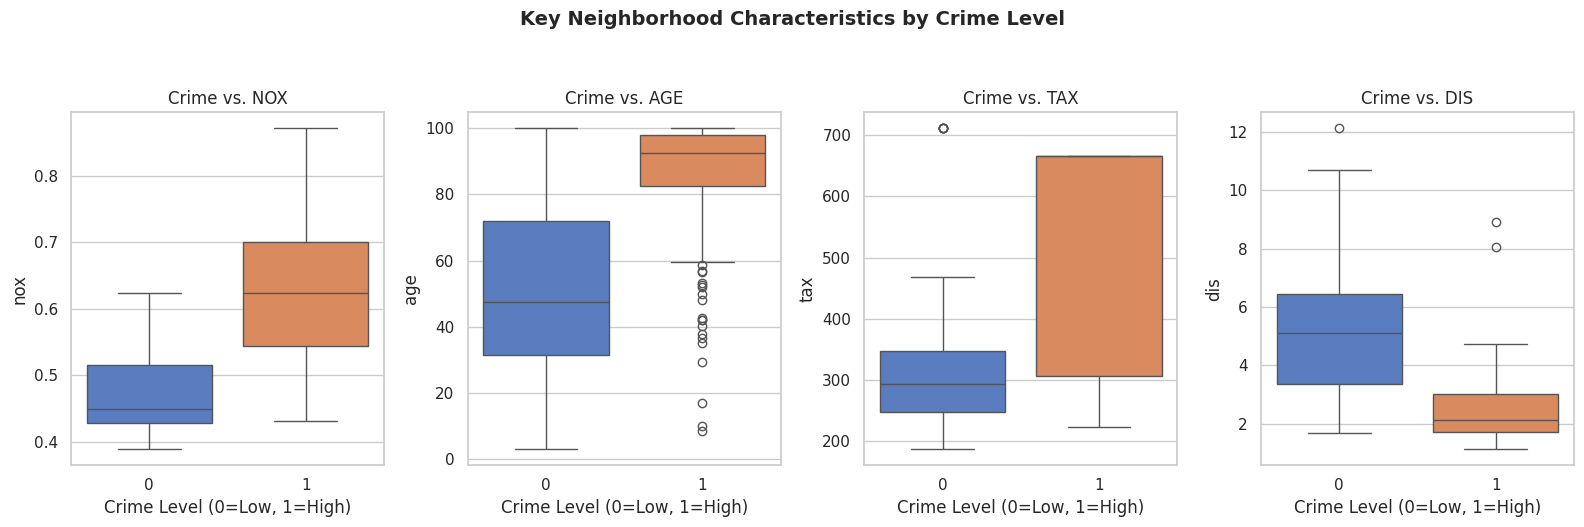

In [4]:
# Select top features to highlight
features_to_plot = ['nox', 'age', 'tax', 'dis']
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, col in enumerate(features_to_plot):
    sns.boxplot(x='target', y=col, data=train_df, ax=axes[i], palette="muted", hue='target', legend=False)
    axes[i].set_title(f"Crime vs. {col.upper()}", fontsize=12)
    axes[i].set_xlabel("Crime Level (0=Low, 1=High)")

plt.suptitle("Key Neighborhood Characteristics by Crime Level", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The boxplots reveal stark contrasts. High-crime neighborhoods (1) are heavily associated with:

- Significantly higher nitrogen oxide pollution (nox).

- Much older housing stock (age).

- Higher property tax rates (tax).

- Closer proximity to urban employment centers (dis is lower).

## 1.4 Correlation & Redundancy (Multicollinearity)

Finally, we must check how strongly these variables correlate with crime, and more importantly, if any of our variables are redundant. Feeding a model highly redundant data causes instability and makes business interpretation difficult.

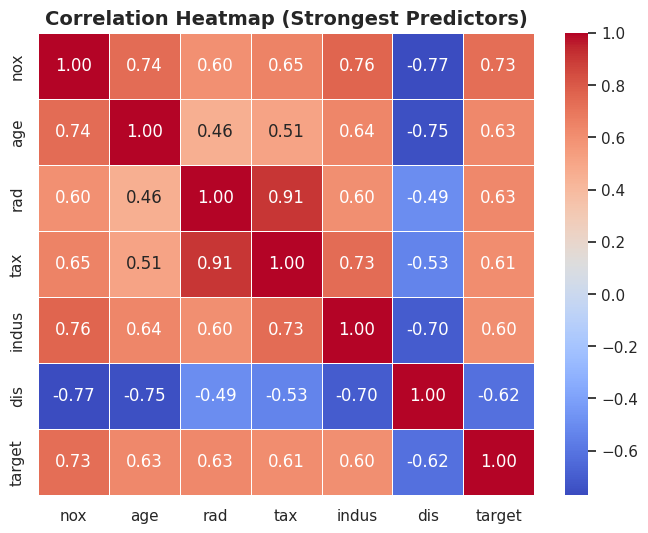

--- Redundancy Alert ---
Correlation between TAX and RAD (Highway Access): 0.91


In [5]:
# Compute correlation matrix
corr_matrix = train_df.corr()

# Isolate correlations with the target
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)

# Plot a focused heatmap of the strongest relationships
plt.figure(figsize=(8, 6))
top_corr_vars = target_corr[abs(target_corr) > 0.5].index.tolist() + ['target']
sns.heatmap(train_df[top_corr_vars].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Strongest Predictors)", fontsize=14, fontweight='bold')
plt.show()

print("--- Redundancy Alert ---")
print(f"Correlation between TAX and RAD (Highway Access): {train_df['tax'].corr(train_df['rad']):.2f}")

Pollution (nox, 0.73) and Highway Accessibility (rad, 0.63) are our strongest single predictors of high crime.

Property tax rates (tax) and highway accessibility (rad) have a massive 0.91 correlation. They are essentially telling us the same thing, likely identifying specific urban zones. Including both in our logistic regression will confuse the model. We should drop one or combine them in the data preparation phase.

# 2. Data preparation

# 3. Build models

# 4. Model selection and predictions

# 5. Final report prep